In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# Regional correlation discovery (NUTS2)
The national screen (notebook 24) has about 30 countries. Here the unit is the **region** (about 230 NUTS2 regions with data in the 2015-19 window, 26 indicators plus derived ratios), which gives far more observations but needs care:
regions of one country share institutions, policy and the national cycle, and neighbours are not independent. So:
- the default screen works **within countries** (each indicator minus its country mean; countries with fewer than 3 regions drop out) and removes the log-GDP-per-head fit;
- robustness drops **whole countries** (leave-one-country-out); the permutation null **shuffles regions inside each country**;
- derived ratios that share a numerator or denominator (output per hour, pay per hour, labour share, hours per inhabitant, investment rate) are not paired with each other;
- Italy is tested with a **placebo ranking** (the same slope difference for every country with at least 5 regions) because Italy is a single cluster.
**Associations only, never causal.** Code: `src/cifresignificative/studies/italy_productivity/analysis/regional_corr.py`, `experiments.py`.

In [2]:
from cifresignificative.studies.italy_productivity.analysis import corr, regional_corr as rc, experiments as ex
reg = load_regional()
res = ex.run_regional_all(reg)
funnel = pd.DataFrame({"survivors": {k: len(v) for k, v in res.items() if k.startswith(("r1", "r2"))},
                       "robust": {k: int(v["robust"].sum()) for k, v in res.items() if k.startswith(("r1", "r2"))}})
display(funnel)
R = rc.regional_matrix(reg, drop_flag_chars="u")
X1 = rc.within_country_table(R, "level", (2015, 2019))
print("regions with data per indicator (2015-19):"); display(X1.notna().sum().sort_values().to_frame("regions").T)
print("discoveries after shuffling regions within countries:", rc.region_permutation_null(X1, n_min=80, n_perm=3))

,survivors,robust
r1_levels_within,165,161
r1_levels_between,88,88
r2_changes_within,59,57


regions with data per indicator (2015-19):


,arope,broadband_households_pct,physicians_per_100k,youth_unemployment_rate,early_leavers_18_24,rd_personnel_pct_employment,rd_pct_gdp,long_term_unemployment_pct_active,fertility_rate,neet_rate_15_29,...,labour_share_pct_gdp,life_expectancy_birth,compensation_per_hour_eur,investment_rate_pct_gdp,hours_per_inhabitant,gfcf_mio_eur,gdp_per_hour_eur,gdp_mio_eur,median_age,hours_ths
regions,137,153,180,183,187,187,187,224,230,230,...,235,235,235,235,235,235,235,235,235,235


discoveries after shuffling regions within countries: [0, 0, 0]


## R1 - within-country associations, 2015-19 (income removed)
Same-theme pairs (labour vs labour, demography vs demography) are near-definitional; the table keeps robust pairs from different themes.

In [3]:
theme_of = reg.assign(indicator=reg.indicator.str.removeprefix("nuts2_")).groupby("indicator").theme.first()
r1 = res["r1_levels_within"]
cross = r1[r1.robust & (r1.x.map(theme_of) != r1.y.map(theme_of))].assign(x_theme=lambda d: d.x.map(theme_of), y_theme=lambda d: d.y.map(theme_of))
display(cross.head(20)[["x", "x_theme", "y", "y_theme", "n", "rho", "q_value"]].round(3))
print("between countries (n = countries):"); display(res["r1_levels_between"].head(8)[["x", "y", "n", "rho", "q_value", "robust"]].round(3))

,x,x_theme,y,y_theme,n,rho,q_value
17,arope,inequality,unemployment_rate,labour,137,0.731,0.0
20,early_leavers_18_24,education,neet_rate_15_29,labour,187,0.707,0.0
22,arope,inequality,employment_rate_20_64_female,labour,137,-0.664,0.0
23,arope,inequality,employment_rate_20_64,labour,137,-0.654,0.0
24,arope,inequality,neet_rate_15_29,labour,137,0.638,0.0
25,arope,inequality,youth_unemployment_rate,labour,109,0.615,0.0
26,rd_personnel_pct_employment,investment,tertiary_attainment_25_64,education,187,0.612,0.0
27,arope,inequality,long_term_unemployment_pct_active,labour,134,0.607,0.0
28,physicians_per_100k,health,tertiary_attainment_25_64,education,178,0.582,0.0
29,arope,inequality,employment_rate_20_64_male,labour,137,-0.581,0.0


between countries (n = countries):


,x,y,n,rho,q_value,robust
0,gdp_per_hour_eur,ln_gdp_pc,27,0.908,0.0,True
1,compensation_per_hour_eur,ln_gdp_pc,27,0.866,0.0,True
2,rd_pct_gdp,rd_personnel_pct_employment,25,0.858,0.0,True
3,net_migration_rate,ln_gdp_pc,27,0.839,0.0,True
4,employment_rate_20_64_male,youth_unemployment_rate,27,-0.832,0.0,True
5,employment_rate_20_64,neet_rate_15_29,27,-0.828,0.0,True
6,unemployment_rate,youth_unemployment_rate,27,0.827,0.0,True
7,employment_rate_20_64,long_term_unemployment_pct_active,27,-0.813,0.0,True


## R2 - within-country associations in changes (2005-09 to 2015-19; break-flagged and provisional values dropped)

In [4]:
display(res["r2_changes_within"].head(15)[["x", "y", "n", "rho", "q_value", "robust"]].round(3))

,x,y,n,rho,q_value,robust
0,long_term_unemployment_pct_active,unemployment_rate,166,0.896,0.0,True
1,unemployment_rate,youth_unemployment_rate,149,0.695,0.0,True
2,employment_rate_20_64,unemployment_rate,193,-0.685,0.0,True
3,rd_pct_gdp,rd_personnel_pct_employment,147,0.681,0.0,True
4,employment_rate_20_64_male,unemployment_rate,193,-0.678,0.0,True
5,employment_rate_20_64,long_term_unemployment_pct_active,166,-0.662,0.0,True
6,employment_rate_20_64_male,long_term_unemployment_pct_active,166,-0.644,0.0,True
7,long_term_unemployment_pct_active,youth_unemployment_rate,140,0.631,0.0,True
8,compensation_per_hour_eur,median_age,162,-0.607,0.0,True
9,neet_rate_15_29,unemployment_rate,186,0.601,0.0,True


## R2b - permutation check of the p-values behind R1 and R2
The pooled Spearman p assumes countries share one dispersion; they do not, and a shuffled test rejects more than the nominal 5%. Here every pair of R1 and R2 is retested with the within-country permutation p (`regional_south.perm_p`, 20,000 shuffles, ranks pooled), BH over all pairs. The funnel's duplicate and robustness steps are not repeated.

In [5]:
from cifresignificative.studies.italy_productivity.analysis import regional_south as rs
chk = pd.DataFrame({k: {"pairs tested": len(res[k]), "BH survivors, asymptotic p": int(res[k].significant_asymptotic.sum()), "BH survivors, permutation p": int(res[k].significant.sum()),
                        "both": int((res[k].significant & res[k].significant_asymptotic).sum()), "share p < 0.05, asymptotic": round(float((res[k].p_asymptotic < 0.05).mean()), 3), "share p < 0.05, permutation": round(float((res[k].p < 0.05).mean()), 3)}
                    for k in ["rp1_levels_perm", "rp2_changes_perm"]})
display(chk)
lost = pd.concat([res[k][res[k].significant_asymptotic & ~res[k].significant].assign(screen=k[:3]) for k in ["rp1_levels_perm", "rp2_changes_perm"]])
print("asymptotic survivors that lose significance under the permutation p:"); display(lost[["screen", "x", "y", "n", "rho", "p_asymptotic", "p", "q_value"]].round(4))
rng = np.random.default_rng(0); g = rc.country_of(X1.index); Xn = X1.drop(columns=corr.size_scaled(X1.columns)); null = []
for k in range(50):
    t = rs.screen_perm(corr.shuffle_within(Xn, g, rng), n_perm=1000, seed=k)
    null.append({"discoveries, asymptotic": int(t.significant_asymptotic.sum()), "discoveries, permutation": int(t.significant.sum()), "share p < 0.05, asymptotic": (t.p_asymptotic < 0.05).mean(), "share p < 0.05, permutation": (t.p < 0.05).mean()})
print("shuffled regions within countries, 50 runs (R1 table), mean:"); display(pd.DataFrame(null).mean().round(3).to_frame("mean"))

,rp1_levels_perm,rp2_changes_perm
pairs tested,284.000,260.000
"BH survivors, asymptotic p",165.000,59.000
"BH survivors, permutation p",164.000,53.000
both,164.000,53.000
"share p < 0.05, asymptotic",0.627,0.308
"share p < 0.05, permutation",0.613,0.315


asymptotic survivors that lose significance under the permutation p:


,screen,x,y,n,rho,p_asymptotic,p,q_value
172,rp1,labour_share_pct_gdp,life_expectancy_birth,235,-0.1431,0.0283,0.0415,0.0682
53,rp2,employment_rate_20_64_female,hours_per_inhabitant,159,0.2123,0.0072,0.0104,0.0503
54,rp2,neet_rate_15_29,old_age_dependency,179,-0.1976,0.0080,0.0107,0.0508
55,rp2,employment_rate_20_64,fertility_rate,191,0.1906,0.0083,0.0115,0.0536
56,rp2,fertility_rate,net_migration_rate,168,0.2027,0.0084,0.0124,0.0566
57,rp2,labour_share_pct_gdp,youth_unemployment_rate,149,-0.2071,0.0113,0.0143,0.0643
59,rp2,early_leavers_18_24,neet_rate_15_29,156,0.2062,0.0098,0.0170,0.0731


shuffled regions within countries, 50 runs (R1 table), mean:


,mean
"discoveries, asymptotic",0.120
"discoveries, permutation",0.000
"share p < 0.05, asymptotic",0.061
"share p < 0.05, permutation",0.050


## R3 - regional hypotheses with region + year fixed effects, SEs clustered by country
The `RH` rows were specified in advance (regional analogues of the literature hypotheses); FDR is applied to them only. `S` rows were picked from the R1 survivors, so their p-values are not independent evidence.

In [6]:
h = res["r3_region_panel"]
display(h[["id", "label", "expected_sign", "coef", "p", "q_value", "sign_agrees", "p_ex_irl", "n_obs", "n_regions"]].round(3))
ll = res["r3_lead_lag"]
display(ll.pivot_table(index=["id", "x", "y"], columns="lag", values="verdict", aggfunc="first"))

,id,label,expected_sign,coef,p,q_value,sign_agrees,p_ex_irl,n_obs,n_regions
0,RH1,Graduate share goes with output per hour,1,0.309,0.035,0.059,True,0.068,2915,213
1,RH2,R&D intensity goes with output per hour,1,-0.052,0.975,0.975,False,0.966,2483,208
2,RH3,Broadband coverage goes with output per hour,1,-0.142,0.000,0.001,False,0.000,2014,164
3,RH4,Graduate share goes with female employment,1,0.125,0.375,0.417,True,0.402,3649,255
4,RH5,Early school leaving goes with NEET,1,0.160,0.013,0.027,True,0.015,2596,222
5,RH6,Net migration goes with (log) regional income ...,1,20.231,0.005,0.017,True,0.010,3703,244
6,RH7,Physician density goes with life expectancy,1,0.001,0.334,0.417,True,0.334,2572,196
7,RH8,Output per hour goes with pay per hour (shares...,1,0.245,0.012,0.027,True,0.000,3903,215
8,RH9,Slack goes with lower investment,-1,-0.453,0.000,0.000,True,0.000,3234,242
9,RH10,Older regions have lower old-age employment,-1,0.352,0.043,0.061,False,0.042,3666,247


,,lag,1,2,3
id,x,y,,,
RH1,tertiary_attainment_25_64,gdp_per_hour_eur,both,y leads,y leads
RH10,old_age_dependency,employment_rate_55_64,x leads,x leads,x leads
RH2,rd_pct_gdp,gdp_per_hour_eur,neither,neither,neither
RH3,broadband_households_pct,gdp_per_hour_eur,both,both,both
RH4,tertiary_attainment_25_64,employment_rate_20_64_female,neither,neither,neither
RH5,early_leavers_18_24,neet_rate_15_29,both,x leads,x leads
RH6,ln_gdp_pc,net_migration_rate,both,both,both
RH7,physicians_per_100k,life_expectancy_birth,neither,neither,neither
RH8,gdp_per_hour_eur,compensation_per_hour_eur,both,both,both


## R4 - is Italy's within-country slope different?
Slope of y on x across regions after removing country means, Italy against all other countries, and the same difference for every other country as a placebo (p = share of countries with an equal or larger |difference|; the smallest possible p is 1 / number of countries). The last columns split Italy into North and South + Islands (exploratory, about 10 regions each).

In [7]:
s = res["r4_italy_slope"]
display(s[["id", "x", "y", "slope_italy", "slope_others", "slope_diff_italy", "p_diff", "n_countries", "slope_north", "slope_south"]].round(3))

,id,x,y,slope_italy,slope_others,slope_diff_italy,p_diff,n_countries,slope_north,slope_south
0,RH1,tertiary_attainment_25_64,gdp_per_hour_eur,1.185,0.549,0.635,0.059,17,-0.178,0.476
1,RH2,rd_pct_gdp,gdp_per_hour_eur,5.368,2.958,2.410,0.429,14,-3.325,3.424
2,RH3,broadband_households_pct,gdp_per_hour_eur,0.978,0.684,0.294,0.833,12,0.130,0.240
3,RH4,tertiary_attainment_25_64,employment_rate_20_64_female,3.150,0.396,2.754,0.056,18,-0.843,3.033
4,RH5,early_leavers_18_24,neet_rate_15_29,1.621,0.810,0.811,0.071,14,0.138,1.031
5,RH6,ln_gdp_pc,net_migration_rate,8.183,4.620,3.563,0.471,17,4.033,8.289
6,RH7,physicians_per_100k,life_expectancy_birth,-0.003,0.003,-0.006,0.188,16,-0.006,0.003
7,RH8,gdp_per_hour_eur,compensation_per_hour_eur,0.354,0.346,0.009,0.941,17,0.266,0.283
8,RH9,unemployment_rate,investment_rate_pct_gdp,-0.178,-0.166,-0.012,0.938,16,-0.396,-0.536
9,RH10,old_age_dependency,employment_rate_55_64,0.575,-0.014,0.589,0.353,17,-0.243,1.250


## R5 - convergence of regional income
Annualised log growth of GDP per head (PPS) between 2005-07 and 2017-19 on the initial log level, country fixed effects, SEs clustered by country. beta < 0 means poorer regions catch up. Second block drops the richest region of each country.

,sample,n_regions,beta,se,p,drop_top_region
0,"all countries (pooled, country FE)",213,-0.114,0.214,0.595,False
1,IT,21,0.469,0.374,0.210,False
2,ES,19,0.655,0.643,0.308,False
3,DE,38,-1.134,0.255,0.000,False
4,FR,26,0.232,0.426,0.585,False
5,PL,17,0.257,0.166,0.121,False
6,"all countries (pooled, country FE)",193,-0.341,0.325,0.295,True
7,IT,20,0.168,0.281,0.549,True
8,ES,18,0.491,0.707,0.487,True
9,DE,37,-1.166,0.334,0.000,True


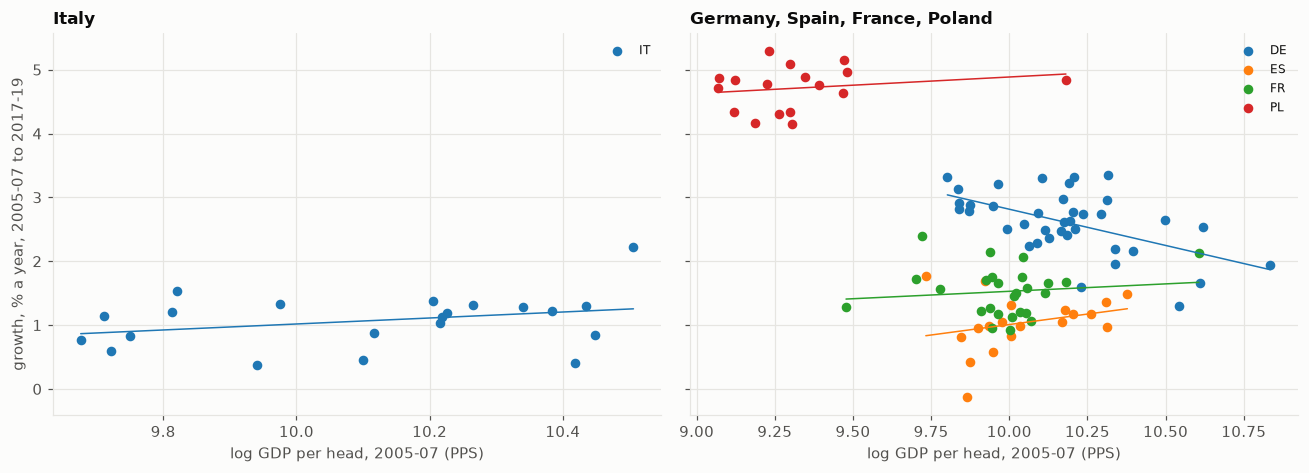

In [8]:
display(res["r5_convergence"].round(3))
lv0 = corr.cross_section(R[["gdp_pps_pc_eu27"]], "level", (2005, 2007), entity_level="geo")["gdp_pps_pc_eu27"]
lv1 = corr.cross_section(R[["gdp_pps_pc_eu27"]], "level", (2017, 2019), entity_level="geo")["gdp_pps_pc_eu27"]
g = pd.DataFrame({"ln0": np.log(lv0), "growth": (np.log(lv1) - np.log(lv0)) / 12 * 100}).dropna()
g["country"] = g.index.str[:2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, cs, title in [(axes[0], ["IT"], "Italy"), (axes[1], ["DE", "ES", "FR", "PL"], "Germany, Spain, France, Poland")]:
    sub = g[g.country.isin(cs)]
    for c, grp in sub.groupby("country"):
        ax.scatter(grp.ln0, grp.growth, label=c, s=28)
        if len(grp) > 3: ax.plot(np.sort(grp.ln0), np.polyval(np.polyfit(grp.ln0, grp.growth, 1), np.sort(grp.ln0)), lw=1)
    ax.set_title(title); ax.set_xlabel("log GDP per head, 2005-07 (PPS)"); ax.legend(fontsize=8)
axes[0].set_ylabel("growth, % a year, 2005-07 to 2017-19")
plt.tight_layout(); plt.show()

## Takeaways (Eurostat NUTS2, 2015-19 unless stated; descriptive associations only)
- **The funnel (within countries, income removed):** 165 pairs survive false-discovery control in the 2015-19 levels (161 pass the leave-one-country-out and rank-vs-linear checks), 59 in the 2005-09 to 2015-19 changes, and 88 between countries (n about 27). Shuffling regions inside countries gives 0 discoveries in 3 runs. Most of the strongest pairs are labour-market pairs (long-term vs total unemployment, employment vs unemployment), so the cross-theme rows are more informative: AROPE with unemployment (rho 0.73, 137 regions), early school leaving with NEET (0.71), R&D personnel and physician density with tertiary attainment (about 0.6).
- **Permutation check (R2b):** retesting every pair with the within-country permutation p keeps 164 of the 165 levels survivors and 53 of the 59 changes survivors; the seven that drop out are weak (|rho| 0.14-0.21, permutation q 0.050-0.073). The check is needed: on shuffled regions the asymptotic p falls below 0.05 in 6.1% of pairs (0.12 discoveries per run, 50 runs), the permutation p in 5.0% (0 discoveries).
- **Pre-specified regional hypotheses (region + year fixed effects, country-clustered SEs):** 5 of 10 are significant at q < 0.05 and 4 go the expected way: early leaving and NEET, net migration and income per head, output and pay per hour (shares the hours denominator), unemployment and the investment rate. Broadband coverage and output per hour move in the *opposite* direction (coefficient -0.14), most likely because coverage saturates while productivity keeps changing. Graduate share and output per hour is borderline (q = 0.059); R&D intensity, graduates and female employment, and physicians and life expectancy show nothing.
- **Cross-sectional links do not survive region fixed effects.** All six AROPE pairs picked from the within-country screen are unrelated once region and year effects are added (p between 0.54 and 0.92; AROPE only starts in 2015), so differences between regions are persistent, not something that moves with time.
- **Lead-lag (1-3 years):** unemployment leads the investment rate (all lags); early leaving leads NEET at 2-3 years; old-age dependency leads old-age employment; output per hour leads the graduate share at 2-3 years (not the reverse); broadband-output, income-migration and output-pay hold in both directions, and R&D, graduates-female employment and physicians-life expectancy show no order.
- **Italy's slopes are the steepest of 14-18 countries in three relations** (graduate share and output per hour 1.18 vs 0.55; graduate share and female employment 3.15 vs 0.40; early leaving and NEET 1.62 vs 0.81), which is the smallest p the placebo ranking can give (1/17, 1/18, 1/14, so p = 0.06 to 0.07): suggestive, not significant, because Italy is one country. They are concentrated in the South and Islands (graduates and female employment: slope 3.03 there, -0.84 in the North; rho 0.79 vs -0.35), and about 10 regions each, so exploratory.
- **Convergence of regional income (2005-07 to 2017-19, country effects):** pooled beta -0.11 (p = 0.60, no convergence), Germany -1.13 (p < 0.001), Italy +0.47 (p = 0.21; +0.17 without the richest region), Spain +0.66, France +0.23, Poland +0.26 (none significant). Italy's South did not catch up with the North in this window.
- **Limits:** about 230 regions but only about 27 countries as clusters; NUTS codes mix vintages (coverage differs by indicator: 137 regions for AROPE, 235 for GDP-based ratios); LFS series carry many break flags (dropped for changes and panels, kept for single-window levels); output per hour uses current prices, not PPPs, so only within-country comparisons are reliable; no causal identification.